# Model Training and Validation Review

This notebook summarizes the results produced by **src/train.py** and **src/evaluate.py**.

Run the following from the repository root before opening this notebook:

1. python -m src.features
2. python -m src.train --models logistic catboost

The notebook reads saved model reports. It does not retrain a model or access Kaggle leaderboard feedback.

## Questions
- Which candidate has the strongest out-of-fold AUROC?
- How stable are scores across folds?
- Which engineered features matter to CatBoost?
- Does the final submission match the required format?

## 1. Load validation artifacts

The training script writes all reports to data/processed, which remains Git-ignored because it contains account-level predictions.

In [2]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import roc_curve, precision_recall_curve

ROOT = Path.cwd()
if not (ROOT / "src" / "train.py").exists():
    ROOT = ROOT.parent

RESULTS = ROOT / "data" / "processed"
assert (RESULTS / "model_summary.csv").exists(), (
    "Run python -m src.train from the repository root first."
)

summary = pd.read_csv(RESULTS / "model_summary.csv")
folds = pd.read_csv(RESULTS / "fold_metrics.csv")
oof = pd.read_csv(RESULTS / "oof_predictions.csv", dtype={"account.id": "string"})
test_predictions = pd.read_csv(
    RESULTS / "test_predictions.csv", dtype={"ID": "string"}
)

with (RESULTS / "run_config.json").open(encoding="utf-8") as f:
    config = json.load(f)

print("Selected model:", config["selected_model"])
print("Validation folds:", config["folds"])
print("Random seed:", config["random_seed"])
print("Training rows:", len(oof))
print("Test rows:", len(test_predictions))

Selected model: catboost
Validation folds: 5
Random seed: 42
Training rows: 6941
Test rows: 2975


## 2. Model comparison

Compare out-of-fold AUROC, fold mean and variability. Average precision is shown as a secondary diagnostic because positive labels are rare.

Choose models using validation results, not public leaderboard iteration.

,model,oof_auc,mean_fold_auc,std_fold_auc,oof_average_precision
0,catboost,0.97139,0.97281,0.00739,0.84040
1,logistic,0.96573,0.96626,0.01294,0.76974


,model,fold,validation_accounts,validation_buyers,roc_auc,average_precision
0,logistic,1,1389,67,0.95111,0.72788
1,logistic,2,1388,66,0.97242,0.81974
2,logistic,3,1388,66,0.98354,0.80397
3,logistic,4,1388,66,0.95622,0.74718
4,logistic,5,1388,67,0.96800,0.80078
5,catboost,1,1389,67,0.96992,0.83524
6,catboost,2,1388,66,0.97269,0.85596
7,catboost,3,1388,66,0.98097,0.88603
8,catboost,4,1388,66,0.96217,0.80464
9,catboost,5,1388,67,0.97829,0.87242


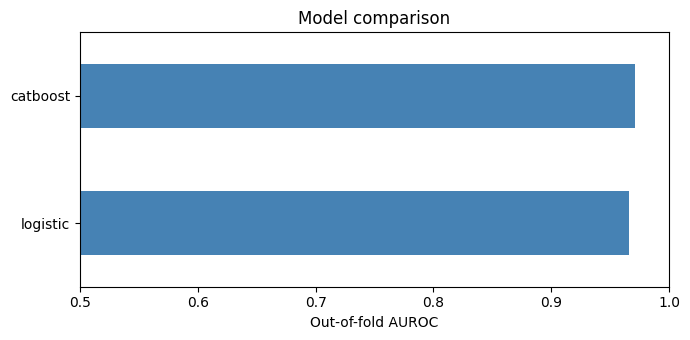

In [3]:
display(summary.round(5))
display(folds.round(5))

ax = summary.set_index("model")["oof_auc"].sort_values().plot(
    kind="barh", figsize=(7, 3.5), color="steelblue"
)
ax.set_xlabel("Out-of-fold AUROC")
ax.set_ylabel("")
ax.set_xlim(0.5, 1.0)
ax.set_title("Model comparison")
plt.tight_layout()
plt.show()

## 3. ROC and precision-recall curves

The curves use **out-of-fold predictions**: every account is scored by a model trained without its label. The precision-recall plot is useful for inspecting the rare positive class, even though Kaggle evaluates AUROC.

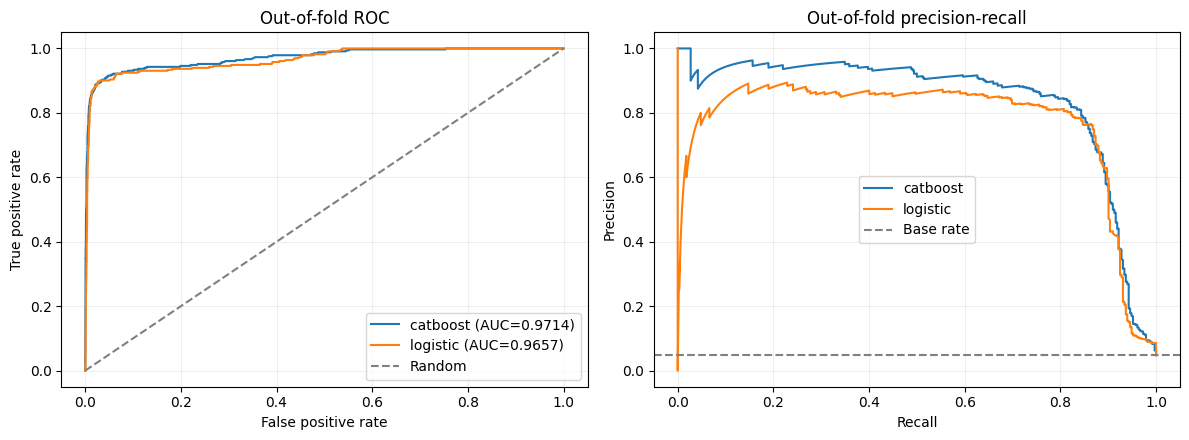

In [4]:
y = oof["label"].to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for name in summary["model"]:
    scores = oof[f"pred_{name}"].to_numpy()
    fpr, tpr, _ = roc_curve(y, scores)
    precision, recall, _ = precision_recall_curve(y, scores)

    auc = summary.set_index("model").loc[name, "oof_auc"]
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={auc:.4f})")
    axes[1].plot(recall, precision, label=name)

axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Random")
axes[0].set(title="Out-of-fold ROC", xlabel="False positive rate",
            ylabel="True positive rate")
axes[1].axhline(y.mean(), color="gray", linestyle="--", label="Base rate")
axes[1].set(title="Out-of-fold precision-recall",
            xlabel="Recall", ylabel="Precision")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

## 4. Score distributions

Inspect whether the selected model ranks known purchasers above non-purchasers. Probability calibration is separate from ranking quality, so this is descriptive rather than a calibration test.

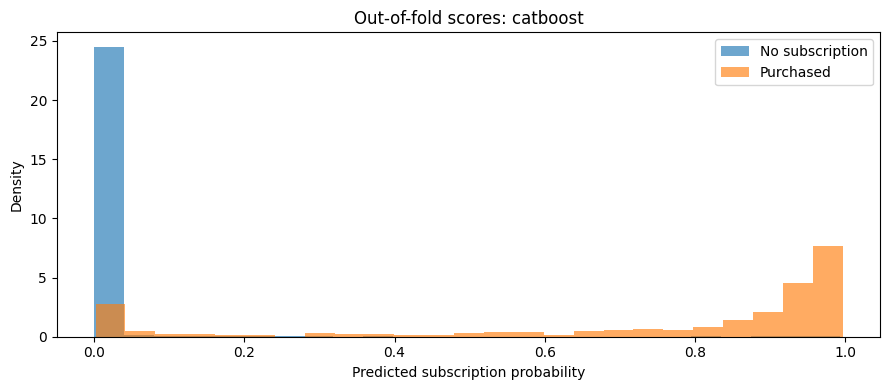

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,6609.0,0.0136,0.0719,0.0001,0.0018,0.0041,0.0076,0.9933
1,332.0,0.7359,0.3358,0.0018,0.6480,0.9083,0.9724,0.9968


In [5]:
selected = config["selected_model"]
score_column = f"pred_{selected}"

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(
    oof.loc[oof["label"] == 0, score_column],
    bins=25, alpha=0.65, density=True, label="No subscription"
)
ax.hist(
    oof.loc[oof["label"] == 1, score_column],
    bins=25, alpha=0.65, density=True, label="Purchased"
)
ax.set(title=f"Out-of-fold scores: {selected}",
       xlabel="Predicted subscription probability",
       ylabel="Density")
ax.legend()
plt.tight_layout()
plt.show()

display(oof.groupby("label")[score_column].describe().round(4))

## 5. CatBoost feature importance

This is shown when CatBoost was evaluated. Importance is averaged across the five fold models. It describes predictive reliance within those models, not causal effects.

,feature,importance_mean,importance_std
0,zip_lat,10.539,1.819
1,sub_last_year,6.898,1.631
2,billing_zip,6.744,2.982
3,zip_long,6.558,2.322
4,sub_active_2013,6.276,2.480
5,sub_recency_seasons,6.140,1.600
6,billing_city,4.888,1.907
7,sub_last_package,4.283,1.162
8,sub_seasons_last_2,4.142,0.971
9,sub_streak_to_2013,3.677,0.907


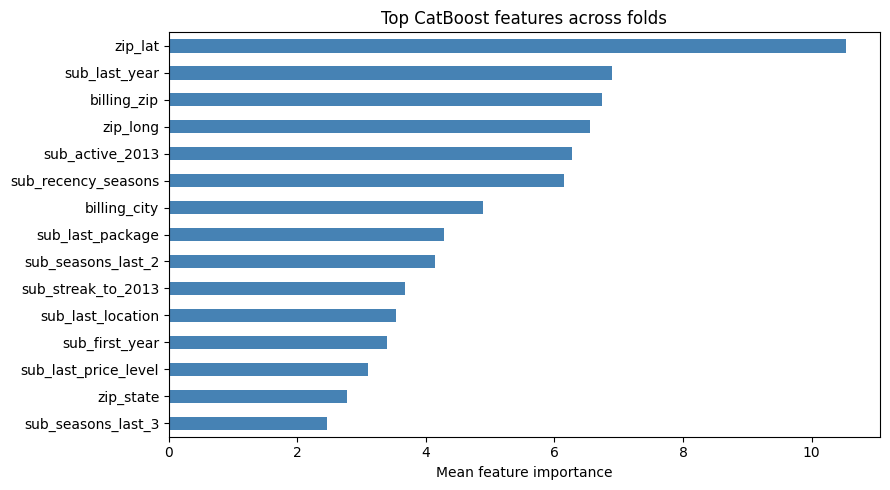

In [6]:
importance_path = RESULTS / "catboost_feature_importance.csv"

if importance_path.exists():
    importance = pd.read_csv(importance_path)
    display(importance.head(20).round(3))

    top = importance.head(15).iloc[::-1]
    ax = top.plot.barh(
        x="feature", y="importance_mean",
        figsize=(9, 5), legend=False, color="steelblue"
    )
    ax.set(xlabel="Mean feature importance", ylabel="",
           title="Top CatBoost features across folds")
    plt.tight_layout()
    plt.show()
else:
    print("CatBoost importance is unavailable. Run the catboost candidate.")

## 6. Kaggle submission verification

The submission must contain exactly 2,975 rows and the column names ID,Predicted. IDs must match the sample submission in the same order. Predicted values must be probabilities between zero and one.

In [7]:
sample = pd.read_csv(
    ROOT / "data" / "raw" / "sample_submission.csv",
    dtype={"ID": "string"}
)
submission = pd.read_csv(
    RESULTS / "submission.csv",
    dtype={"ID": "string"}
)

assert submission.columns.tolist() == sample.columns.tolist()
assert len(submission) == len(sample) == 2975
assert submission["ID"].equals(sample["ID"])
assert submission["ID"].is_unique
assert np.isfinite(submission["Predicted"]).all()
assert submission["Predicted"].between(0, 1).all()

print("Submission format checks passed.")
display(submission["Predicted"].describe(
    percentiles=[0.01, 0.10, 0.50, 0.90, 0.99]
).to_frame(name="Predicted"))

Submission format checks passed.


,Predicted
count,2975.000000
mean,0.049145
std,0.186336
min,0.000254
1%,0.000472
10%,0.001336
50%,0.004753
90%,0.017439
99%,0.970403
max,0.990802


## 7. Conclusions and next experiments

### Baseline performance
_Fill in the best out-of-fold AUROC and fold-to-fold variability._

### Most useful feature groups
_Summarize the feature importance results and any unexpected findings._

### Next experiments
- Test recency-only features against the complete feature set
- Evaluate carefully designed recent-activity and retention features
- Audit source timing for lifetime donations and ZIP economics before inclusion
- Compare CatBoost tuning choices with the same validation procedure
- Keep the public Kaggle leaderboard separate from model selection

Clear patron-level notebook outputs before sharing the repository if the competition data is restricted.